## Tentative d'affichage d'image 

Pour valider que données sont représentées comme valeurs de pixels dans le fichier csv des données

_importations_

In [2]:
import pandas as pnd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split # pip install requests scikit-learn
import tensorflow as tf # pip install requests tensorflow
import keras # pip install requests keras

I0000 00:00:1793369322.647003  102777 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793369322.647290  102777 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793369322.671235  102777 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793369323.310565  102777 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

### Définition de la largeur et longueur de l'image et chargement de l'image

In [4]:
tf.config.set_visible_devices([], 'GPU')

LONGUEUR_IMAGE = 28
LARGEUR_IMAGE = 28

observations_entrainement = pnd.read_csv('../datas/fichiersLabAnalyse_images/fashion-mnist_train.csv')

Afficher l'image à partir des pixels décrits dans le fichier csv

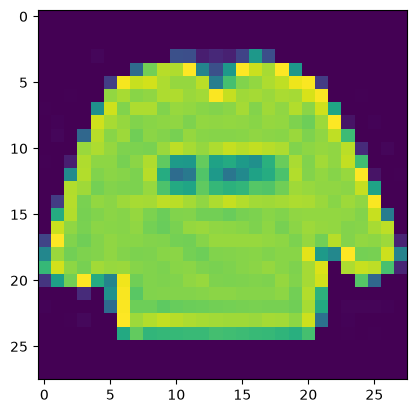

In [5]:
X = np.array(observations_entrainement.iloc[:, 1:])

premiereImage = X[0]
premiereImage = premiereImage.reshape([LONGUEUR_IMAGE,LARGEUR_IMAGE])
plt.imshow(premiereImage)
plt.show()

## Préparation des données d'apprentissage

### Créer les jeux d’apprentissage et de tests 

Créer des catégories à l'aide du module Keras. Puis répartir des données d'entrainement en données d'apprentissage et données de validation (80% de donnée d'apprentissage et 20% de donnée de validation)

In [6]:
y = keras.utils.to_categorical(np.array(observations_entrainement.iloc[:,0]))
X_apprentissage, X_validation, y_apprentissage, y_validation = train_test_split(X, y, test_size=0.2, random_state=13)

Redimensionner les images au format 28*28 et réaliser un scaling sur les données des pixels

In [7]:
X_apprentissage = X_apprentissage.reshape(X_apprentissage.shape[0], 
                                          LARGEUR_IMAGE, 
                                          LONGUEUR_IMAGE, 1)
X_apprentissage = X_apprentissage.astype('float32')
X_apprentissage /= 255

X_validation = X_validation.reshape(X_validation.shape[0], 
                                    LARGEUR_IMAGE, 
                                    LONGUEUR_IMAGE, 1)
X_validation = X_validation.astype('float32')
X_validation /= 255

Préparation des données tests

In [9]:
observations_test = pnd.read_csv('../datas/fichiersLabAnalyse_images/fashion-mnist_train.csv')
X_test = np.array(observations_test.iloc[:, 1:])
y_test = tf.keras.utils.to_categorical(np.array(observations_test.iloc[:, 0]))
X_test = X_test.reshape(X_test.shape[0], 
                        LARGEUR_IMAGE, 
                        LONGUEUR_IMAGE, 1)
X_test = X_test.astype('float32')
X_test /= 255

## Configuration d'un réseau de neurones

Liste des configurations : 
- Une couche de convolution de 32 filtres de taille 3x3 avec une fonction d’activation de type ReLU
- Un pooling composé d’un filtre de 2x2
- Une phase de flatten (mise en colonne des résultats du pooling)
- Un réseau de neurones complètement connecté de 128 neurones avec une fonction d’activation de type ReLU
- Un dernier réseau de neurones complètement connecté comportant 10 neurones et une fonction - d’activation de type Softmax correspondant aux 10 catégories d’images à prédire

In [10]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Input
from keras.layers import Conv2D, MaxPooling2D

# On spécifie les dimensions de l'image d'entrée
dimentionImage = (LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

# On crée le réseau de neurones couche par couche
reseauNeurone1Convolution = Sequential()

# Ajout de la couche d'entrée
reseauNeurone1Convolution.add(Input(shape=dimentionImage))

#1- Ajout de la couche de convolution comportant
# 32 filtres de de taille 3x3 (Kernel) parcourant l'image
# Une fonction d'activation de type ReLU (Rectified Linear Activation)
# Une image d'entrée de 28px * 28 px 
reseauNeurone1Convolution.add(Conv2D(32, 
                                     kernel_size=(3, 3), 
                                     activation='relu'))

#2- Définition de la fonction de pooling avec une fenêtre de 2px sur 2 px
reseauNeurone1Convolution.add(MaxPooling2D(pool_size=(2, 2)))

#3- Ajout d'une fonction d'ignorance
reseauNeurone1Convolution.add(Dropout(0.2))

#5 - On transforme en une seule ligne
reseauNeurone1Convolution.add(Flatten())

#6 - Ajout d'un réseau de neurones composé de 128 neurones avec 
# une fonction d'activation de type ReLU
reseauNeurone1Convolution.add(Dense(128, activation='relu'))

#7 - Ajout d'un réseau de neurones composé de 10 neurones avec une 
# fonction d'activation de type softmax
reseauNeurone1Convolution.add(Dense(10, activation='softmax'))

## Compilser et réaliser l'apprentissage du réseau

In [11]:
reseauNeurone1Convolution.compile(loss=keras.losses.categorical_crossentropy, 
                                  optimizer=tf.keras.optimizers.Adam(), 
                                  metrics=['accuracy'])

Paramétrer l'apprentissage ainsi :

- 10 passages complets du jeu de données à travers le réseau de neurones (epoch)
- 256 images traitées à la fois (batch_size)
- Un affichage des logs d’apprentissage dans la console (verbose=1)
- La validation du modèle est basée sur les images et labels de validation définis plus en amont de ce chapitre (80 % de données d’apprentissage et 20 % de données de validation)

In [12]:
historique_apprentissage = reseauNeurone1Convolution.fit(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256,
    epochs=10,
    verbose=1,
    validation_data=(X_validation, y_validation))

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.8021 - loss: 0.5650 - val_accuracy: 0.8555 - val_loss: 0.4072
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.8727 - loss: 0.3641 - val_accuracy: 0.8833 - val_loss: 0.3326
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.8883 - loss: 0.3180 - val_accuracy: 0.8878 - val_loss: 0.3174
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.8956 - loss: 0.2927 - val_accuracy: 0.8954 - val_loss: 0.2940
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9028 - loss: 0.2733 - val_accuracy: 0.8974 - val_loss: 0.2869
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9071 - loss: 0.2572 - val_accuracy: 0.9018 - val_loss: 0.2748
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9118 - loss: 0.2443 - val_accuracy: 0.9022 - val_loss: 0.2720
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9178 - loss: 0.2296 - val_accu

### Évaluation du modèle d’apprentissage sur les données de tests afin de déterminer la précision d’apprentissage

In [15]:
evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur:', evaluation[0])
print('Précision:', evaluation[1])

Erreur: 0.19203157722949982
Précision: 0.9325500130653381


Nous avons une précision de classification de 93,25 % avec un taux d’erreur de 19,20 %.

### Affichage de graphique des courbes de précision et d’erreur après chaque passage complet du jeu de données à travers le réseau de neurones (epoch)

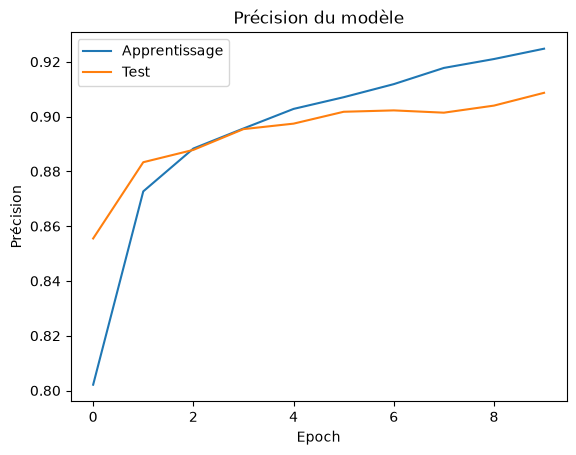

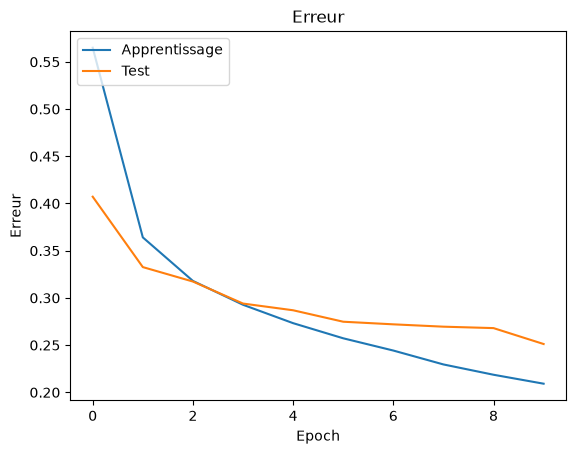

In [14]:
plt.plot(historique_apprentissage.history['accuracy'])
plt.plot(historique_apprentissage.history['val_accuracy'])
plt.title('Précision du modèle')
plt.ylabel('Précision')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()

plt.plot(historique_apprentissage.history['loss'])
plt.plot(historique_apprentissage.history['val_loss'])
plt.title('Erreur')
plt.ylabel('Erreur')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()

Nous observons que l'erreur diminue par passage complet du jeu de données à travers le réseau de neurones et la précison augmente par passage complet du jeu de données à travers le réseau de neurones.

## Augmentation du nombre d’images du jeu d’apprentissage

Avec la fonction ImageDataGenerator du module Keras

In [16]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

generateur_images = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=8,
    width_shift_range=0.08,
    shear_range=0.3,
    height_shift_range=0.08,
    zoom_range=0.08)

### Générer de nouvelles images et procéder à un nouvel apprentissage.

In [18]:
nouvelles_images_apprentissage = generateur_images.flow(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256)

nouvelles_images_validation = generateur_images.flow(
    X_validation, 
    y_validation,
    batch_size=256)

historique_apprentissage = reseauNeurone1Convolution.fit(
    nouvelles_images_apprentissage,
    steps_per_epoch=48000//256,
    epochs=50,
    validation_data=nouvelles_images_validation,
    validation_steps=12000//256,
    verbose=1 )

evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)

print('Erreur :', evaluation[0])
print('Précision:', evaluation[1])

Epoch 1/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 6s 31ms/step - accuracy: 0.8932 - loss: 0.2874 - val_accuracy: 0.8905 - val_loss: 0.2981
Epoch 2/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9141 - loss: 0.2602 - val_accuracy: 0.8921 - val_loss: 0.2932
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 6s 31ms/step - accuracy: 0.8933 - loss: 0.2847 - val_accuracy: 0.8854 - val_loss: 0.3015
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9023 - loss: 0.2899 - val_accuracy: 0.8810 - val_loss: 0.3084
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.8949 - loss: 0.2826 - val_accuracy: 0.8936 - val_loss: 0.2897
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8867 - loss: 0.3207 - val_accuracy: 0.8894 - val_loss: 0.3001
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.8971 - loss: 0.2799 - val_accuracy: 0.8911 - val_loss: 0.2909
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9141 - loss: 0.2371 - val_accuracy

## Sauvegarde du modèle

In [21]:
model_json = reseauNeurone1Convolution.to_json() 
with open("../datas/fichiersLabAnalyse_images/fashion-mnist_train.csv", "w") as json_file:
    json_file.write(model_json)
    
reseauNeurone1Convolution.save_weights("../modele/modele.weights.h5")
print("Modèle sauvegardé !")

Modèle sauvegardé !


## Augmentation de la performance du modèle avec 4 couches de convolution

In [22]:
from keras.layers import BatchNormalization

reseauNeurones4Convolution = Sequential()

reseauNeurones4Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=dimentionImage))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(MaxPooling2D(pool_size=(2, 2)))
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Conv2D(64, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Conv2D(128, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(MaxPooling2D(pool_size=(2, 2)))
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Flatten())
reseauNeurones4Convolution.add(Dense(512, activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.5))

reseauNeurones4Convolution.add(Dense(128, activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.5))

reseauNeurones4Convolution.add(Dense(10, activation='softmax'))

/home/cano/repos/420-5G4-ML-nbc/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### Lancement de l'apprentissage du modèle à performance augmentée

In [23]:
reseauNeurones4Convolution.compile(loss=keras.losses.categorical_crossentropy, 
                                  optimizer=tf.keras.optimizers.Adam(), 
                                  metrics=['accuracy'])

historique_apprentissage = reseauNeurones4Convolution.fit(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256,
    epochs=10,
    verbose=1,
    validation_data=(X_validation, y_validation))

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 12s 57ms/step - accuracy: 0.7395 - loss: 0.7618 - val_accuracy: 0.2380 - val_loss: 2.9041
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 56ms/step - accuracy: 0.8395 - loss: 0.4517 - val_accuracy: 0.6139 - val_loss: 1.2912
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 57ms/step - accuracy: 0.8662 - loss: 0.3729 - val_accuracy: 0.8155 - val_loss: 0.4993
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 56ms/step - accuracy: 0.8796 - loss: 0.3327 - val_accuracy: 0.8965 - val_loss: 0.2825
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 56ms/step - accuracy: 0.8900 - loss: 0.3061 - val_accuracy: 0.8952 - val_loss: 0.2925
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - accuracy: 0.8993 - loss: 0.2827 - val_accuracy: 0.8996 - val_loss: 0.2790
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 10s 56ms/step - accuracy: 0.9037 - loss: 0.2689 - val_accuracy: 0.9034 - val_loss: 0.2573
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 57ms/step - accuracy: 0.9074 - loss: 0.2586 - 

Évaluation des résultats du modèle plus performant

In [24]:
evaluation = reseauNeurones4Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur:', evaluation[0])
print('Précision:', evaluation[1])

Erreur: 0.1857534497976303
Précision: 0.9302833080291748


Nous avons une précision de classification de 93,03 % avec un taux d’erreur de 18,58 %. le taux d'erreur a légèrement diminué.

Utilisation d'encore plus de données

In [25]:
historique_apprentissage = reseauNeurones4Convolution.fit(
    nouvelles_images_apprentissage,
    steps_per_epoch=48000//256,
    epochs=50,
    validation_data=nouvelles_images_validation,
    validation_steps=12000//256,
    verbose=1 )

evaluation = reseauNeurones4Convolution.evaluate(X_test, y_test, verbose=0)

print('Erreur :', evaluation[0])
print('Précision:', evaluation[1])

Epoch 1/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 11s 56ms/step - accuracy: 0.8569 - loss: 0.3974 - val_accuracy: 0.8811 - val_loss: 0.3250
Epoch 2/50
  1/187 ━━━━━━━━━━━━━━━━━━━━ 10s 58ms/step - accuracy: 0.8750 - loss: 0.3243

/home/cano/repos/420-5G4-ML-nbc/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8750 - loss: 0.3243 - val_accuracy: 0.8775 - val_loss: 0.3328
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - accuracy: 0.8702 - loss: 0.3571 - val_accuracy: 0.8627 - val_loss: 0.3791
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8633 - loss: 0.3679 - val_accuracy: 0.8619 - val_loss: 0.3794
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - accuracy: 0.8755 - loss: 0.3451 - val_accuracy: 0.8726 - val_loss: 0.3301
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9023 - loss: 0.3230 - val_accuracy: 0.8719 - val_loss: 0.3307
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - accuracy: 0.8794 - loss: 0.3304 - val_accuracy: 0.8775 - val_loss: 0.3188
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8789 - loss: 0.3851 - val_accuracy: 0.8815 - val_loss: 0.3067
Epoch 9/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - accuracy: 0.8837 - loss: 0.3176 - val_accuracy: 0.887